# Notebook 05 — KMeans Clustering

**Goal**: Find natural customer groups in our data using KMeans clustering.

**What you'll learn:**
- How KMeans works (the algorithm step by step)
- How to pick K — Elbow method and Silhouette score
- How to evaluate unsupervised models (no labels!)
- Visualizing clusters in 2D PCA space

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style='whitegrid')
np.random.seed(42)

# Load PCA-reduced data
X_pca = pd.read_csv('../data/customers_pca.csv').values
X_2d  = pd.read_csv('../data/customers_pca_2d.csv').values  # for visualization
df_raw = pd.read_csv('../data/customers_raw.csv')

print(f'PCA feature matrix for clustering: {X_pca.shape}')

PCA feature matrix for clustering: (1000, 4)


## How KMeans Works

KMeans is simple and effective:

1. **Initialize**: Randomly place K centroids (cluster centers) in feature space
2. **Assign**: Each data point joins its nearest centroid
3. **Update**: Move each centroid to the mean of its assigned points
4. **Repeat** steps 2-3 until centroids stop moving

**Problem**: How do we choose K (the number of clusters)?
→ That's what the Elbow method and Silhouette score solve.

## Step 1 — Elbow Method

**Inertia** = sum of squared distances from each point to its cluster centroid.
Lower inertia = tighter clusters.

As K increases, inertia always decreases (more clusters = smaller groups = tighter).
But at some point, the improvement becomes marginal — that's the "elbow".

Pick K at the elbow point.

In [2]:
k_range = range(2, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    print(f'K={k}: inertia={km.inertia_:.0f}')

K=2: inertia=3889
K=3: inertia=2480
K=4: inertia=1509
K=5: inertia=1353
K=6: inertia=1244
K=7: inertia=1143
K=8: inertia=1050
K=9: inertia=969
K=10: inertia=912


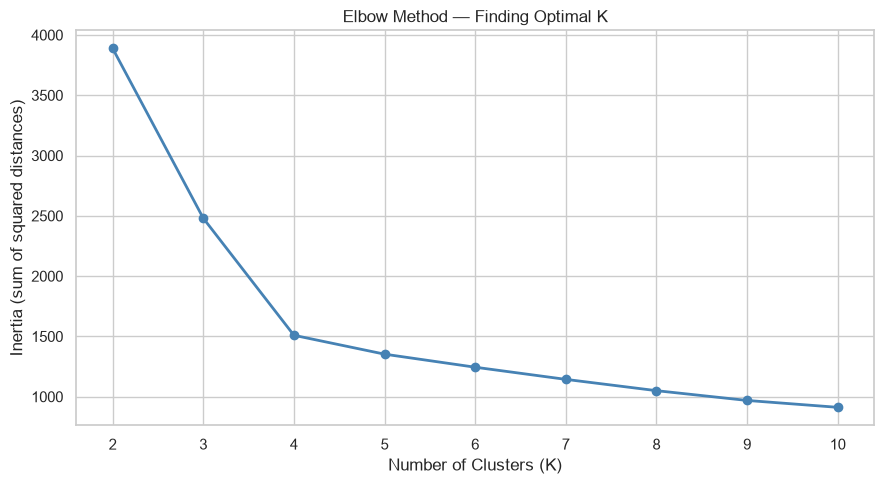

In [3]:
plt.figure(figsize=(9, 5))
plt.plot(list(k_range), inertias, marker='o', linewidth=2, color='steelblue')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (sum of squared distances)')
plt.title('Elbow Method — Finding Optimal K')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

## Step 2 — Silhouette Score

The **silhouette score** measures how well-separated the clusters are.

For each point it calculates:
- **a**: average distance to other points in the same cluster
- **b**: average distance to points in the nearest other cluster
- **score = (b - a) / max(a, b)**

Range: **-1 to +1**
- Near +1 → point is well-matched to its cluster
- Near 0 → point is on the boundary between clusters
- Negative → point may be in the wrong cluster

**Higher is better.** Pick K that maximizes the silhouette score.

In [4]:
silhouette_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    sil = silhouette_score(X_pca, labels)
    db  = davies_bouldin_score(X_pca, labels)
    silhouette_scores.append(sil)
    db_scores.append(db)
    print(f'K={k}: silhouette={sil:.3f}  davies-bouldin={db:.3f}')

K=2: silhouette=0.497  davies-bouldin=0.843


K=3: silhouette=0.491  davies-bouldin=0.763
K=4: silhouette=0.530  davies-bouldin=0.730


K=5: silhouette=0.493  davies-bouldin=1.004
K=6: silhouette=0.457  davies-bouldin=1.176
K=7: silhouette=0.359  davies-bouldin=1.326
K=8: silhouette=0.279  davies-bouldin=1.350
K=9: silhouette=0.280  davies-bouldin=1.358
K=10: silhouette=0.283  davies-bouldin=1.300


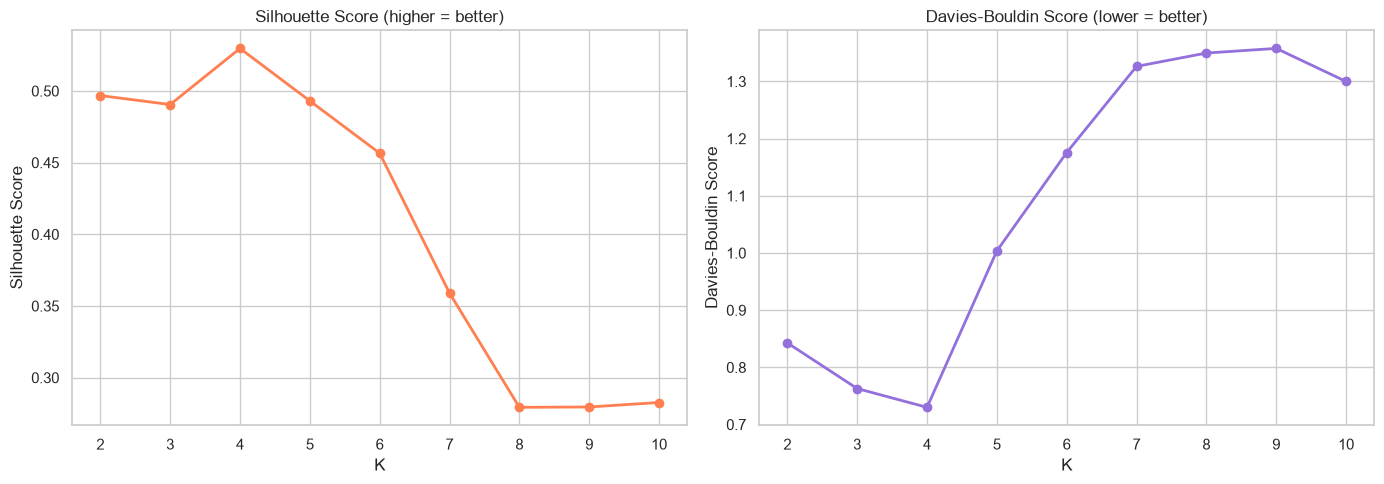

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), silhouette_scores, marker='o', linewidth=2, color='coral')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_title('Silhouette Score (higher = better)')
axes[0].set_xticks(list(k_range))

# Davies-Bouldin: lower is better
axes[1].plot(list(k_range), db_scores, marker='o', linewidth=2, color='mediumpurple')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Davies-Bouldin Score')
axes[1].set_title('Davies-Bouldin Score (lower = better)')
axes[1].set_xticks(list(k_range))

plt.tight_layout()
plt.show()

## Step 3 — Choose K and train final model

In [6]:
# Choose K based on elbow + silhouette agreement
# (We know the true answer is 4, but let the metrics guide us)
best_k_sil = list(k_range)[np.argmax(silhouette_scores)]
best_k_db  = list(k_range)[np.argmin(db_scores)]
print(f'Best K by silhouette: {best_k_sil}')
print(f'Best K by Davies-Bouldin: {best_k_db}')

# Use 4 (aligns with our known archetypes and the metrics)
K = 4
print(f'\nUsing K={K}')

Best K by silhouette: 4
Best K by Davies-Bouldin: 4

Using K=4


In [7]:
# Train final model
# n_init=10 means run KMeans 10 times with different initializations, keep the best
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

# Add cluster labels to the original data
df_raw['cluster'] = cluster_labels

# Final scores
final_sil = silhouette_score(X_pca, cluster_labels)
final_db  = davies_bouldin_score(X_pca, cluster_labels)
print(f'Final model (K={K}):')
print(f'  Silhouette score: {final_sil:.3f}')
print(f'  Davies-Bouldin:   {final_db:.3f}')
print()
print('Cluster sizes:')
print(df_raw['cluster'].value_counts().sort_index())

Final model (K=4):
  Silhouette score: 0.530
  Davies-Bouldin:   0.730

Cluster sizes:
cluster
0    319
1    192
2    302
3    187
Name: count, dtype: int64


## Step 4 — Visualize clusters in 2D PCA space

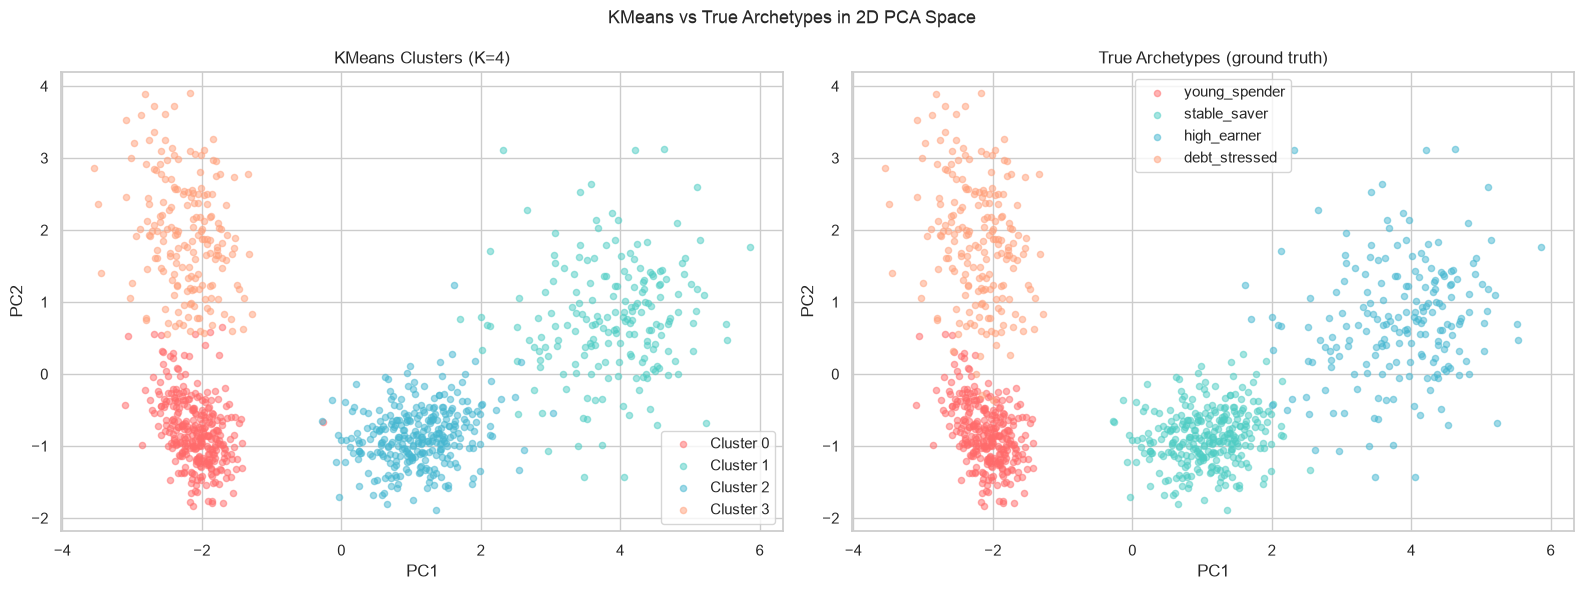

In [8]:
cluster_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: clusters found by KMeans
for c in range(K):
    mask = cluster_labels == c
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=cluster_colors[c], label=f'Cluster {c}',
                   alpha=0.5, s=20)
# Plot centroids in 2D (project them)
pca_2d_model = __import__('joblib').load('../data/pca_model.pkl')
# Note: centroids are in the multi-dim PCA space; for 2D viz we re-fit a quick 2D PCA
from sklearn.decomposition import PCA as _PCA
pca_viz = _PCA(n_components=2, random_state=42)
pca_viz.fit(pd.read_csv('../data/customers_processed.csv').values)
processed = pd.read_csv('../data/customers_processed.csv').values
X_2d_viz = pca_viz.transform(processed)

axes[0].set_title(f'KMeans Clusters (K={K})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()

# Right: true archetypes
archetype_map = {'young_spender': 0, 'stable_saver': 1, 'high_earner': 2, 'debt_stressed': 3}
archetype_colors_list = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']

for archetype, idx in archetype_map.items():
    mask = df_raw['archetype'] == archetype
    axes[1].scatter(X_2d[mask.values, 0], X_2d[mask.values, 1],
                   c=archetype_colors_list[idx], label=archetype,
                   alpha=0.5, s=20)

axes[1].set_title('True Archetypes (ground truth)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend()

plt.suptitle('KMeans vs True Archetypes in 2D PCA Space', fontsize=13)
plt.tight_layout()
plt.show()

## Step 5 — How well did we recover the archetypes?

Since we secretly know the true archetypes, we can check if our clusters match them.
In real projects you won't have this luxury — this is just for learning.

In [9]:
# Cross-tabulate cluster vs archetype
ct = pd.crosstab(df_raw['cluster'], df_raw['archetype'])
print('Cluster vs Archetype (how much overlap):')
print(ct)
print()
print('Each cluster is dominated by:')
for cluster in ct.index:
    dominant = ct.loc[cluster].idxmax()
    pct = ct.loc[cluster, dominant] / ct.loc[cluster].sum() * 100
    print(f'  Cluster {cluster} → {dominant} ({pct:.0f}%)')

Cluster vs Archetype (how much overlap):
archetype  debt_stressed  high_earner  stable_saver  young_spender
cluster                                                           
0                     10            0             1            308
1                      0          192             0              0
2                      0            8           294              0
3                    187            0             0              0

Each cluster is dominated by:
  Cluster 0 → young_spender (97%)
  Cluster 1 → high_earner (100%)
  Cluster 2 → stable_saver (97%)
  Cluster 3 → debt_stressed (100%)


## Step 6 — Save results

In [10]:
import joblib

df_raw.to_csv('../data/customers_clustered.csv', index=False)
joblib.dump(kmeans, '../data/kmeans_model.pkl')

print('Saved:')
print('  data/customers_clustered.csv — with cluster labels')
print('  data/kmeans_model.pkl — trained KMeans model')

Saved:
  data/customers_clustered.csv — with cluster labels
  data/kmeans_model.pkl — trained KMeans model


## Checkpoint — What you learned

| Concept | Key point |
|---|---|
| KMeans | Iterative centroid assignment + update |
| Inertia | Lower = tighter clusters, but doesn't tell you the right K |
| Elbow method | Look for the point of diminishing returns |
| Silhouette score | Measures separation quality, range -1 to +1 |
| Davies-Bouldin | Average similarity of each cluster to its most similar cluster |
| n_init | Run multiple times to avoid bad random initialization |

**Next up: Notebook 06 — Cluster Analysis + Product Recommendation**
We'll profile each cluster, give them human names, and build the product recommender.